# Module 2: X-Ray Fracture Detection with DenseNet121

Binary classification pipeline: Fracture vs. No Fracture

- **Model**: DenseNet121 (ImageNet pretrained)
- **Dataset A** (Structured): train/, val/, test/ with fractured/ and not fractured/ subfolders
- **Dataset B** (Unstructured): fracture/ and normal/ folders (manual 70/15/15 split)
- **Training**: Two-phase fine-tuning with early stopping
- **Device**: CUDA if available, CPU fallback

## Kaggle Datasets
- Dataset A: https://www.kaggle.com/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data
- Dataset B: https://www.kaggle.com/datasets/orvile/bone-fracture-dataset

## GitHub Repository
This notebook automatically clones the required modules from:
- **Branch**: `feat/module2`
- **Repo**: https://github.com/MaroSalah02/X-CV
- **Path**: Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection

**Cell 1** will handle the GitHub setup automatically. Just run it first!

## How to Add Your GitHub Token to Kaggle

For accessing **private GitHub repositories**, you need to add your GitHub Personal Access Token to Kaggle Secrets:

### Step 1: Create GitHub Personal Access Token
1. Go to https://github.com/settings/tokens
2. Click **"Generate new token"** → **"Generate new token (classic)"**
3. Name it: `X-CV-Kaggle`
4. Select scopes: ✅ `repo` (full control of private repositories)
5. Click **"Generate token"**
6. **Copy the token** (you won't see it again!)

### Step 2: Add Token to Kaggle Notebook
1. Open this notebook in Kaggle
2. Click **⚙️ Settings** (top right)
3. Go to **Add-ons** → **Secrets**
4. Click **+ Add new secret**
5. Key: `GITHUB_TOKEN`
6. Value: **Paste your token**
7. Click **Save**

### Step 3: Run the Notebook
- Cell 1 will automatically load the token from Kaggle Secrets
- The notebook will clone the private repository
- All modules will be imported and ready to use

### ⚠️ Security Notes
- Never commit your token to GitHub
- Tokens are stored encrypted in Kaggle
- You can regenerate tokens anytime at https://github.com/settings/tokens
- The token is only used within this notebook

In [13]:
# ============ Setup: GitHub Repository / Local Path ============
import subprocess
import os
import sys
from urllib.parse import urljoin

# Check if running on Kaggle
is_kaggle = os.path.exists('/kaggle/input')

if not is_kaggle:
    print("Running in local environment.")
    # If we are already in the project structure, we don't need to clone
    if os.path.exists('data_preprocessing.py'):
        print("✓ Local modules found. Skipping clone.")
        module_path = os.getcwd()
    else:
        # Check if we are in the root and the workspace exists
        workspace_path = 'Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection'
        if os.path.exists(workspace_path):
            print(f"✓ Found workspace at {workspace_path}")
            module_path = os.path.abspath(workspace_path)
        else:
            print("⚠ Local modules not found. Might need to clone or check directory structure.")
            module_path = None
else:
    # ============ GitHub Token Setup (Kaggle Only) ============
    try:
        from kaggle_secrets import UserSecretsClient
        user_secrets = UserSecretsClient()
        github_token = user_secrets.get_secret("GITHUB_TOKEN")
        print("✓ GitHub token loaded from Kaggle Secrets")
    except Exception as e:
        print(f"⚠ Could not load from Kaggle Secrets: {e}")
        github_token = None

    # ============ Repository Configuration ============
    repo_url = "https://github.com/MaroSalah02/X-CV.git"
    branch = "feat/module2"
    module_dir = "Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection"
    clone_dir = "x-cv-repo"

    # ============ Clone Repository ============
    if not os.path.exists(clone_dir):
        print("\n" + "="*70)
        print("Cloning GitHub Repository")
        print("="*70)
        try:
            if github_token:
                auth_url = repo_url.replace("https://", f"https://{github_token}@")
                clone_cmd = ["git", "clone", "--branch", branch, "--depth", "1", auth_url, clone_dir]
            else:
                clone_cmd = ["git", "clone", "--branch", branch, "--depth", "1", repo_url, clone_dir]
            
            subprocess.run(clone_cmd, check=True, capture_output=True, text=True)
            print("✓ Repository cloned successfully")
        except Exception as e:
            print(f"✗ Git clone failed: {e}")
            raise
    else:
        print(f"✓ Repository already exists in {clone_dir}")
    
    module_path = os.path.abspath(os.path.join(clone_dir, module_dir))

# ============ Setup Python Path ============
if module_path and module_path not in sys.path:
    sys.path.insert(0, module_path)
    print(f"✓ Module path added: {module_path}")

# ============ Standard Imports ============
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

# Set seaborn style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# ============ Import Custom Modules ============
print("\nImporting custom modules...")
try:
    from data_preprocessing import (
        get_combined_dataloader,
        show_batch,
        get_class_weights
    )
    from model import (
        build_densenet121,
        unfreeze_layers,
        get_model_summary
    )
    from train import (
        train_model,
        plot_training_history,
        load_model
    )
    from evaluate_module2 import (
        evaluate_on_test,
        predict_single_image
    )
    print("✓ All custom modules imported successfully")
except ImportError as e:
    print(f"✗ Import error: {e}")
    raise

print("\n" + "="*70)
print("Environment Information")
print("="*70)
print(f"PyTorch version: {torch.__version__}")
print(f"TorchVision version: {torchvision.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("="*70)
print("✓ Setup completed successfully!\n")

✓ GitHub token loaded from Kaggle Secrets
✓ Repository already exists in x-cv-repo

Importing custom modules...
✓ All custom modules imported successfully

Environment Information
PyTorch version: 2.10.0+cu128
TorchVision version: 0.25.0+cu128
NumPy version: 2.0.2
CUDA available: True
GPU: Tesla T4
✓ Setup completed successfully!



In [14]:
# ============ Troubleshooting: Alternative Setup Methods ============
# Use this ONLY if Cell 1 failed

"""
import urllib.request
import zipfile
import shutil
import base64

# Method 1: Using GitHub Token with ZIP Download
def setup_from_github_zip_with_token(github_token):
    '''Download private repo as ZIP using GitHub token'''
    # GitHub API to get archive link
    owner = "MaroSalah02"
    repo = "X-CV"
    branch = "feat/module2"
    
    zip_url = f"https://github.com/{owner}/{repo}/archive/refs/heads/{branch}.zip"
    zip_path = "x-cv-repo.zip"
    
    print("Downloading repository as ZIP...")
    
    # Create auth header
    headers = {'Authorization': f'token {github_token}'}
    request = urllib.request.Request(zip_url, headers=headers)
    
    try:
        with urllib.request.urlopen(request) as response:
            with open(zip_path, 'wb') as out_file:
                out_file.write(response.read())
        print("✓ Repository downloaded")
    except Exception as e:
        print(f"✗ Download failed: {e}")
        return False
    
    print("Extracting repository...")
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(".")
        
        # Find and setup the module path
        module_base = f"X-CV-{branch}/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection"
        if os.path.exists(module_base):
            sys.path.insert(0, module_base)
            print(f"✓ Module path added: {module_base}")
            os.remove(zip_path)
            return True
        else:
            print(f"✗ Module path not found at: {module_base}")
            return False
    except Exception as e:
        print(f"✗ Extraction failed: {e}")
        return False

# Method 2: Using Git with SSH (if you have SSH key configured)
def setup_from_github_ssh():
    '''Clone using SSH key (requires SSH key setup in Kaggle)'''
    repo_url = "git@github.com:MaroSalah02/X-CV.git"
    branch = "feat/module2"
    clone_dir = "x-cv-repo"
    
    try:
        subprocess.run(
            ["git", "clone", "--branch", branch, "--depth", "1", repo_url, clone_dir],
            check=True,
            capture_output=True
        )
        print("✓ Repository cloned via SSH")
        return True
    except subprocess.CalledProcessError as e:
        print(f"✗ SSH clone failed: {e.stderr}")
        return False

# UNCOMMENT AND RUN ONE OF THESE IF CELL 1 FAILED:

# Option A: If you have the token available here
# github_token = "your_token_here"  # Replace with your actual token
# success = setup_from_github_zip_with_token(github_token)

# Option B: If you have SSH configured
# success = setup_from_github_ssh()

print("✓ Troubleshooting options available. Uncomment one above if needed.")
"""

print("✓ Troubleshooting cell loaded. Use only if Cell 1 fails.")

✓ Troubleshooting cell loaded. Use only if Cell 1 fails.


In [15]:
# ============ Path Configuration ============
import os

def get_dataset_paths():
    # Kaggle-specific paths
    KAGGLE_A = '/kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification'
    KAGGLE_B = '/kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset'
    
    # Local development paths (relative to notebook or project root)
    # Try different potential locations in the project structure
    potential_bases = [
        '.',
        '..',
        '../..',
        '../../../..', # If in x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection
        '../../Datasets - Unsplit/X-Ray Fracture Detection',
        '../../Datasets - Raw/X-Ray Fracture Detection'
    ]
    
    # Check if running on Kaggle
    if os.path.exists('/kaggle/input'):
        print("✓ Running on Kaggle environment")
        return KAGGLE_A, KAGGLE_B

    print("Running in local environment. Searching for datasets...")
    
    for base in potential_bases:
        path_a = os.path.join(base, 'Bone_Fracture_Binary_Classification')
        path_b = os.path.join(base, 'Bone fracture dataset')
        
        if os.path.exists(path_a):
            print(f"✓ Found Dataset A at: {os.path.abspath(path_a)}")
            return path_a, path_b
            
        # Also check inside 'input' folder if it exists
        input_a = os.path.join(base, 'input', 'Bone_Fracture_Binary_Classification')
        input_b = os.path.join(base, 'input', 'Bone fracture dataset')
        if os.path.exists(input_a):
            print(f"✓ Found Dataset A at: {os.path.abspath(input_a)}")
            return input_a, input_b

    # Default fallback
    default_a = './Bone_Fracture_Binary_Classification'
    default_b = './Bone fracture dataset'
    
    print("⚠ ERROR: Could not find dataset directories!")
    print("Please download the datasets and place them in the following folder:")
    print(f"  {os.path.abspath(os.getcwd())}")
    print("Expected folder names:")
    print("  - Bone_Fracture_Binary_Classification")
    print("  - Bone fracture dataset")
    return default_a, default_b

ROOT_A, ROOT_B = get_dataset_paths()

BATCH_SIZE = 32
NUM_EPOCHS = 30
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
SAVE_DIR = './weights'

# Create weights directory
os.makedirs(SAVE_DIR, exist_ok=True)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)
torch.backends.cudnn.deterministic = True

print("="*70)
print("Configuration")
print("="*70)
print(f"Dataset A root: {ROOT_A}")
print(f"Dataset B root: {ROOT_B}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Number of epochs: {NUM_EPOCHS}")
print(f"Device: {DEVICE}")
print(f"Save directory: {SAVE_DIR}")
if DEVICE == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print("="*70)

✓ Running on Kaggle environment
Configuration
Dataset A root: /kaggle/input/datasets/bmadushanirodrigo/fracture-multi-region-x-ray-data/Bone_Fracture_Binary_Classification/Bone_Fracture_Binary_Classification
Dataset B root: /kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset
Batch size: 32
Number of epochs: 30
Device: cuda
Save directory: ./weights
GPU: Tesla T4


Loading dataloaders with deduplication and augmentation...


Hashing Dataset A (train):   0%|          | 0/9246 [00:00<?, ?it/s]

[train - Dataset A] Original: 9246 | Removed: 5469 duplicate(s).


Hashing Dataset B (train):   0%|          | 0/1488 [00:00<?, ?it/s]

[train - Dataset B] Original: 1488 | Removed: 634 duplicate(s).
Applying data augmentation targeting 2324 items per class...


...

[val - Dataset B] Original: 319 | Removed: 161 duplicate(s).


Hashing Dataset A (test):   0%|          | 0/506 [00:00<?, ?it/s]

[test - Dataset A] Original: 506 | Removed: 496 duplicate(s).


Hashing Dataset B (test):   0%|          | 0/320 [00:00<?, ?it/s]

[test - Dataset B] Original: 320 | Removed: 182 duplicate(s).

Dataset Information
Training batches: 146
Validation batches: 9
Test batches: 5
Total training samples: 4648
Total validation samples: 259
Total test samples: 148

Visualizing training batch...


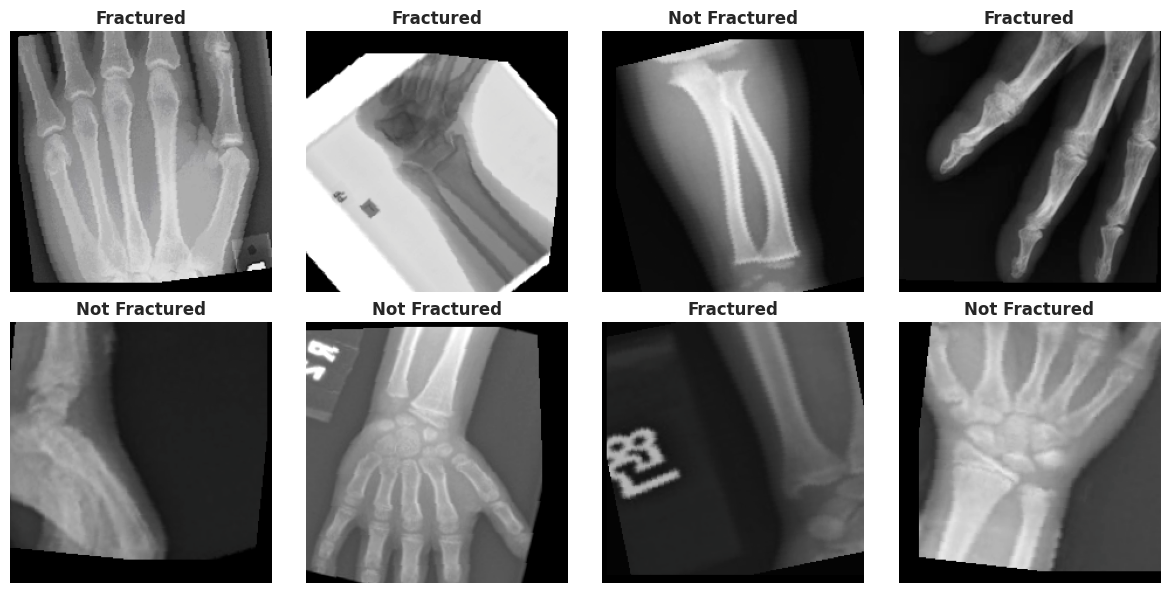

In [16]:
import hashlib
import numpy as np
from tqdm.auto import tqdm
import torch
from torch.utils.data import DataLoader, ConcatDataset, Subset, WeightedRandomSampler, Dataset
from PIL import Image, ImageOps, ImageChops

# Global cache for deduplication across all dataset splits based on image content hashing
seen_hashes = set()

def get_file_hash(filepath):
    hasher = hashlib.md5()
    try:
        with open(filepath, 'rb') as f:
            buf = f.read()
            hasher.update(buf)
        return hasher.hexdigest()
    except Exception:
        return None

def filter_duplicates(dataset, phase, name):
    global seen_hashes
    valid_indices = []
    
    # Extract paths based on dataset type: ImageFolder or Subset
    if hasattr(dataset, 'imgs'):
        paths = [path for path, label in dataset.imgs]
    elif hasattr(dataset, 'indices') and hasattr(dataset.dataset, 'image_paths'):
        paths = [dataset.dataset.image_paths[i] for i in dataset.indices]
    else:
        print(f"[{phase}] Unknown dataset format for {name}. Returning as-is.")
        return dataset
        
    for i, path in enumerate(tqdm(paths, desc=f"Hashing {name} ({phase})")):
        h = get_file_hash(path)
        if h is None:
            continue
        if h not in seen_hashes:
            seen_hashes.add(h)
            valid_indices.append(i)
            
    print(f"[{phase} - {name}] Original: {len(paths)} | Removed: {len(paths) - len(valid_indices)} duplicate(s).")
    return Subset(dataset, valid_indices)

class AugmentedDatasetWrapper(Dataset):
    def __init__(self, dataset, target_count, augmentation_params):
        self.dataset = dataset
        self.target_count = target_count
        self.params = augmentation_params
        
        # Determine items per class
        class_indices = {}
        for idx in range(len(dataset)):
            try:
                _, label = dataset[idx]
                label = int(label)
                if label not in class_indices:
                    class_indices[label] = []
                class_indices[label].append(idx)
            except Exception:
                continue
                
        self.augmented_indices = []
        self.augmentation_metadata = []
        
        for label, indices in class_indices.items():
            current_count = len(indices)
            self.augmented_indices.extend(indices)
            self.augmentation_metadata.extend([None] * current_count)
            
            if current_count < target_count:
                aug_needed = target_count - current_count
                np.random.seed(self.params.get("generation_seed", 42))
                selected_idx = np.random.choice(indices, size=aug_needed, replace=True)
                
                for idx in selected_idx:
                    self.augmented_indices.append(idx)
                    self.augmentation_metadata.append({
                        "rotation": np.random.uniform(-self.params.get("rotation_range", 0), self.params.get("rotation_range", 0)),
                        "flipping": self.params.get("flipping", False) and np.random.choice([True, False]),
                        "inverting": self.params.get("inverting", False) and np.random.choice([True, False]),
                        "vertical_shift": np.random.uniform(-self.params.get("shift_range", 0), self.params.get("shift_range", 0)),
                        "horizontal_shift": np.random.uniform(-self.params.get("shift_range", 0), self.params.get("shift_range", 0))
                    })
                    
    def __len__(self):
        return len(self.augmented_indices)
        
    def __getitem__(self, idx):
        real_idx = self.augmented_indices[idx]
        meta = self.augmentation_metadata[idx]
        image, label = self.dataset[real_idx]
        
        if meta and isinstance(image, torch.Tensor):
            # Convert tensor back to PIL for augmentations (since Transforms apply at loading time, we reverse temporarily)
            from torchvision.transforms import ToPILImage, ToTensor
            image = ToPILImage()(image)
            
            if meta["rotation"] != 0:
                image = image.rotate(meta["rotation"], resample=Image.BILINEAR)
            if meta["flipping"]:
                image = ImageOps.mirror(image)
            if meta["inverting"]:
                image = ImageOps.invert(image)
            if meta["vertical_shift"] != 0 or meta["horizontal_shift"] != 0:
                shift_x = int(meta["horizontal_shift"] * image.width)
                shift_y = int(meta["vertical_shift"] * image.height)
                image = ImageChops.offset(image, shift_x, shift_y)
                
            image = ToTensor()(image)
            
        return image, label

def get_dedup_combined_dataloader(root_A: str, root_B: str, phase: str, batch_size: int = 32, num_workers: int = 4):
    from data_preprocessing import get_dataset_A, get_dataset_B, get_class_weights
    
    dataset_a = get_dataset_A(root_A, phase=phase)
    dataset_b = get_dataset_B(root_B, phase=phase)
    
    dataset_a_filtered = filter_duplicates(dataset_a, phase, "Dataset A")
    dataset_b_filtered = filter_duplicates(dataset_b, phase, "Dataset B")
    
    combined_dataset = ConcatDataset([dataset_a_filtered, dataset_b_filtered])
    
    if phase == 'train':
        augmentation_params = {
            "rotation_range": 15,
            "flipping": True,
            "inverting": True,
            "shift_range": 0.1,
            "generation_seed": 42
        }
        
        # Compute min count logic to match dataset preparer structure or simply set a target
        # For simplicity we set target per class derived from current lengths safely
        # or a fixed target like 3000. We'll use 5000 arbitrarily, or max class count.
        class_counts = {0: 0, 1: 0}
        for idx in range(len(combined_dataset)):
            try:
                _, label = combined_dataset[idx]
                class_counts[int(label)] += 1
            except Exception: continue
        target_count = max(class_counts.values()) # Upsample minority to match majority
        print(f"Applying data augmentation targeting {target_count} items per class...")
        
        combined_dataset = AugmentedDatasetWrapper(combined_dataset, target_count, augmentation_params)
        
        class_weights = get_class_weights(combined_dataset)
        sample_weights = []
        for idx in range(len(combined_dataset)):
            try:
                _, label = combined_dataset[idx]
                sample_weights.append(class_weights[int(label)])
            except Exception:
                sample_weights.append(0.0)
                
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        dataloader = DataLoader(combined_dataset, batch_size=batch_size, sampler=sampler, num_workers=num_workers)
    else:
        dataloader = DataLoader(combined_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
        
    return dataloader

# Load dataloaders for all phases
print("Loading dataloaders with deduplication and augmentation...")
train_loader = get_dedup_combined_dataloader(ROOT_A, ROOT_B, phase='train', batch_size=BATCH_SIZE)
val_loader = get_dedup_combined_dataloader(ROOT_A, ROOT_B, phase='val', batch_size=BATCH_SIZE)
test_loader = get_dedup_combined_dataloader(ROOT_A, ROOT_B, phase='test', batch_size=BATCH_SIZE)

print("\n" + "="*70)
print("Dataset Information")
print("="*70)
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")
print(f"Total training samples: {len(train_loader.dataset)}")
print(f"Total validation samples: {len(val_loader.dataset)}")
print(f"Total test samples: {len(test_loader.dataset)}")
print("="*70)

# Visualize a batch
print("\nVisualizing training batch...")
show_batch(train_loader, n=8)

In [17]:
# Build model
print("Building DenseNet121 model...")
model = build_densenet121(
    num_classes=2,
    pretrained=True,
    dropout_rate=0.5
)
model = model.to(DEVICE)

# Print model summary
get_model_summary(model)

print("\nModel architecture (first 5 layers):")
for i, (name, module) in enumerate(model.named_children()):
    if i < 5:
        print(f"  {name}: {module.__class__.__name__}")

Building DenseNet121 model...
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 30.8M/30.8M [00:00<00:00, 101MB/s] 


Model Summary
Input size:              (1, 3, 224, 224)
Total parameters:        7,480,706
Trainable parameters:    526,850
Non-trainable parameters: 6,953,856
Trainable ratio:         7.04%

Model architecture (first 5 layers):
  features: Sequential
  classifier: Sequential


In [18]:
# Train the model
print("\nStarting training...\n")
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    num_epochs=NUM_EPOCHS,
    device=DEVICE,
    save_dir=SAVE_DIR,
    patience=7
)

print("\nTraining completed!")

/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:199: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()



Starting training...


Training on cuda
Total epochs: 30

[Phase 1] Training classifier head only (frozen backbone)


Training:   0%|          | 0/146 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]                       /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/30] Train Loss: 0.6200, Train Acc: 65.58% | Val Loss: 0.3093, Val Acc: 90.73%
  ✓ Best model saved (Val Acc: 90.73%)


Training:   0%|          | 0/146 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]                       /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

Epoch [28/30] Train Loss: 0.1589, Train Acc: 93.42% | Val Loss: 0.0719, Val Acc: 97.68%


Training:   0%|          | 0/146 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]                       /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [29/30] Train Loss: 0.1706, Train Acc: 92.99% | Val Loss: 0.0799, Val Acc: 97.30%


Training:   0%|          | 0/146 [00:00<?, ?it/s]/kaggle/working/x-cv-repo/Model Fine-tuning/Models Workspaces/X-Ray Fracture Detection/train.py:100: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
Evaluating:   0%|          | 0/9 [00:00<?, ?it/s]                       /usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [30/30] Train Loss: 0.1693, Train Acc: 93.07% | Val Loss: 0.0749, Val Acc: 97.68%
Training completed!
Best Val Acc: 98.46% (Epoch 24)
Models saved to: ./weights

Training completed!


Plotting training history...


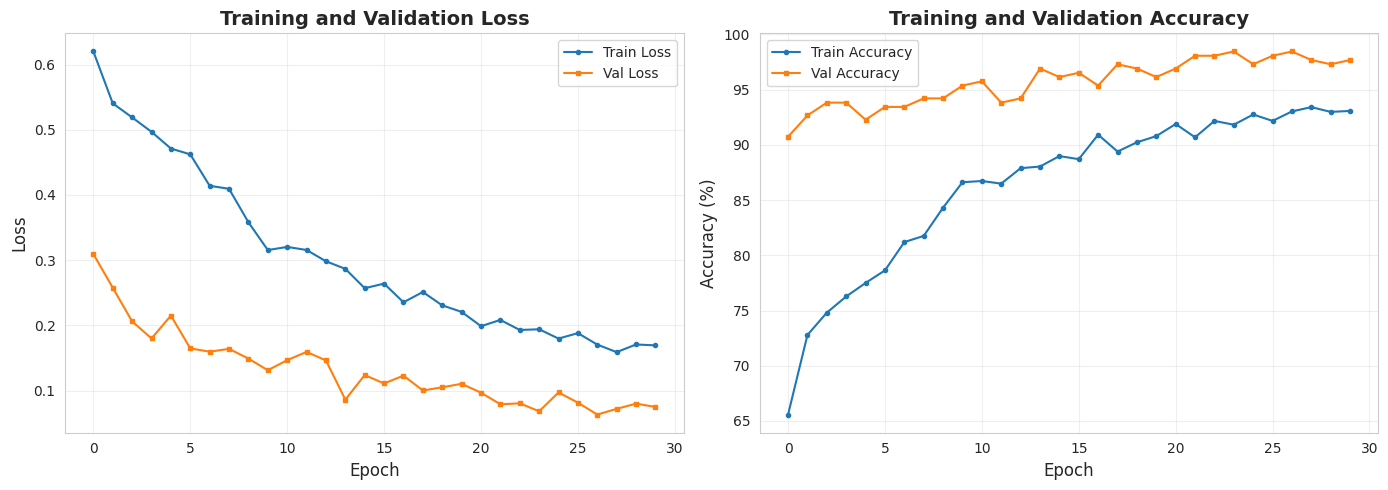


Final Training Metrics
Best validation accuracy: 98.46%
Final training loss: 0.1693
Final validation loss: 0.0749


In [19]:
# Plot training curves
print("Plotting training history...")
plot_training_history(history)

# Print final metrics
print("\n" + "="*70)
print("Final Training Metrics")
print("="*70)
print(f"Best validation accuracy: {max(history['val_acc']):.2f}%")
print(f"Final training loss: {history['train_loss'][-1]:.4f}")
print(f"Final validation loss: {history['val_loss'][-1]:.4f}")
print("="*70)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Model loaded from: ./weights/densenet121_best.pth

Evaluating on test set...


Test evaluation: 100%|██████████| 5/5 [00:00<00:00,  5.15it/s]



Classification Report
               precision    recall  f1-score   support

Not Fractured     0.0000    0.0000    0.0000         1
    Fractured     0.9932    0.9864    0.9898       147

     accuracy                         0.9797       148
    macro avg     0.4966    0.4932    0.4949       148
 weighted avg     0.9864    0.9797    0.9831       148

Confusion Matrix
[[  0   1]
 [  2 145]]


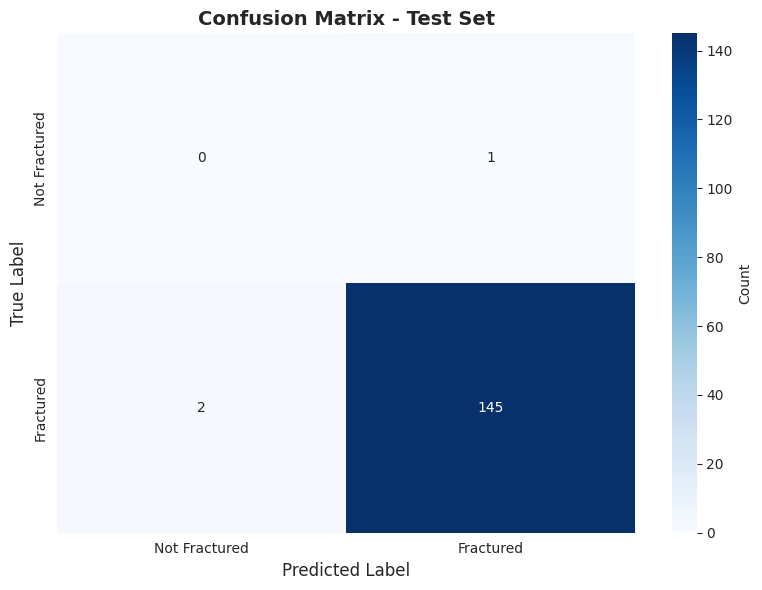

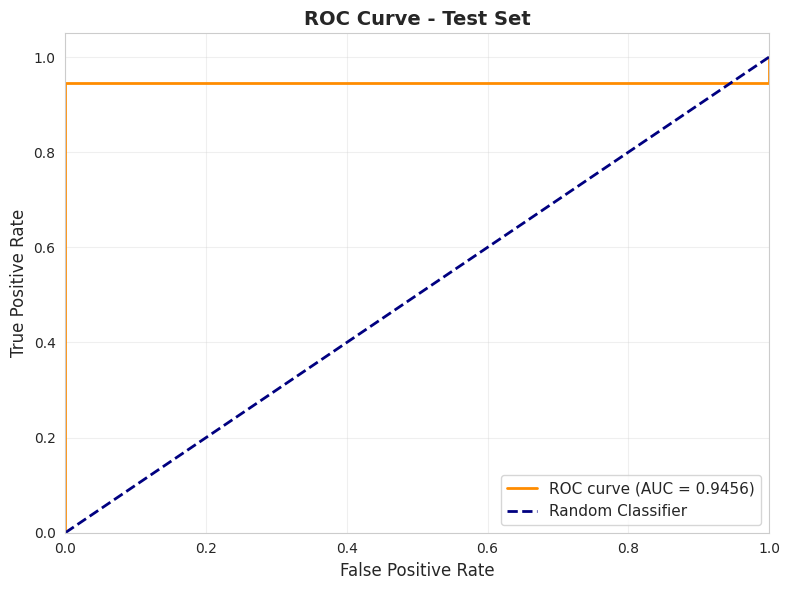

ROC AUC Score: 0.9456


In [20]:
# Load best model
best_model = load_model(
    checkpoint_path=os.path.join(SAVE_DIR, 'densenet121_best.pth'),
    device=DEVICE
)

# Evaluate on test set
evaluate_on_test(best_model, test_loader, DEVICE)

In [26]:
# Example: Single image prediction
# Replace 'sample_xray.jpg' with actual image path
sample_image_path = '/kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset/fracture/0.png'

# Check if sample image exists
if os.path.exists(sample_image_path):
    print(f"Predicting on: {sample_image_path}\n")
    result = predict_single_image(
        best_model,
        sample_image_path,
        device=DEVICE
    )
    
    print("="*70)
    print("Prediction Result")
    print("="*70)
    print(f"Prediction: {result['prediction']}")
    print(f"Confidence: {result['confidence']:.4f}")
    print(f"\nProbabilities:")
    for class_name, prob in result['probabilities'].items():
        print(f"  {class_name}: {prob:.4f}")
    print("="*70)
else:
    print(f"Sample image not found at: {sample_image_path}")
    print("To test single image prediction, provide a valid image path.")
    print("\nExample usage:")
    print("  result = predict_single_image(best_model, 'path/to/image.jpg', device=DEVICE)")
    print("  print(result)")

Predicting on: /kaggle/input/datasets/orvile/bone-fracture-dataset/Bone fracture dataset/Bone fracture dataset/Dataset/fracture/0.png

Prediction Result
Prediction: Fractured
Confidence: 0.9978

Probabilities:
  Fractured: 0.9978
  Not Fractured: 0.0022
